In [1]:
import sys
import torch
from pathlib import Path

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("GPU 可用:", torch.cuda.is_available())

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}:", torch.cuda.get_device_name(i))

output_dir = Path("/kaggle/working/member_a_results")
output_dir.mkdir(parents=True, exist_ok=True)
print("结果目录:", output_dir)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
GPU 可用: True
GPU 0: Tesla T4
GPU 1: Tesla T4
结果目录: /kaggle/working/member_a_results


In [2]:
import sys
import json
import hashlib
import subprocess
import tarfile
import shutil
from pathlib import Path

BASE = Path("/kaggle/working")
REPO = BASE / "checklist"
OUT = BASE / "member_a_results"
OUT.mkdir(parents=True, exist_ok=True)

def run_step(args, log_name, cwd=None):
    result = subprocess.run(
        args,
        cwd=cwd,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        errors="replace",
    )
    (OUT / log_name).write_text(result.stdout, encoding="utf-8")
    if result.returncode != 0:
        print(result.stdout[-12000:])
        raise RuntimeError(f"步骤失败，日志：{log_name}")
    return result.stdout

# 1. 只安装推理所需库，保留现有 PyTorch
print("1/3 安装推理依赖……", flush=True)
run_step(
    [
        sys.executable, "-m", "pip", "install",
        "transformers==4.57.1",
    ],
    "install_transformers.log",
)

# 2. 获取官方仓库，固定到之前使用的版本
print("2/3 下载官方实验材料……", flush=True)
if not REPO.exists():
    run_step(
        ["git", "clone", "https://github.com/marcotcr/checklist.git",
         str(REPO)],
        "clone.log",
    )

CHECKLIST_COMMIT = "4e6e5e33a26f30c20ed602b2050f6c73e123cc23"
run_step(
    ["git", "checkout", "--detach", CHECKLIST_COMMIT],
    "checkout.log",
    cwd=REPO,
)

suite_path = REPO / "release_data/sentiment/sentiment_suite.pkl"
if not suite_path.exists():
    with tarfile.open(REPO / "release_data.tar.gz", "r:gz") as tar:
        tar.extractall(REPO, filter="data")

# 3. 将评分必需的材料一起放入结果目录，方便后续完整备份
print("3/3 检查并保存实验来源……", flush=True)
source = REPO / "release_data/sentiment"
reference = OUT / "reference"
reference.mkdir(exist_ok=True)

files_to_copy = {
    "tests_n500": "tests_n500",
    "sentiment_suite.pkl": "sentiment_suite.pkl",
    "predictions/bert": "official_bert_predictions.txt",
    "predictions/roberta": "official_roberta_predictions.txt",
}

hashes = {}
for src_name, dst_name in files_to_copy.items():
    src = source / src_name
    assert src.is_file(), f"缺少文件：{src}"
    dst = reference / dst_name
    shutil.copy2(src, dst)
    hashes[dst_name] = hashlib.sha256(dst.read_bytes()).hexdigest()

with (reference / "tests_n500").open(encoding="utf-8") as f:
    n_texts = sum(1 for _ in f)

assert n_texts == 87470, f"文本数量与上次不一致：{n_texts}"

provenance = {
    "checklist_commit": CHECKLIST_COMMIT,
    "n_texts": n_texts,
    "sha256": hashes,
    "models": {
        "bert": {
            "id": "textattack/bert-base-uncased-SST-2",
            "revision": "95f0f6f859b35c8ff0863ae3cd4e2dbc702c0ae2",
        },
        "roberta": {
            "id": "textattack/roberta-base-SST-2",
            "revision": "84ee248b91053ef5d0c748bbac4edfba1cf89584",
        },
    },
}
(OUT / "experiment_config.json").write_text(
    json.dumps(provenance, indent=2), encoding="utf-8"
)

print("\n官方源码版本:", CHECKLIST_COMMIT)
print("测试文本数:", n_texts)
print("结果目录:", OUT)
print("KAGGLE_SETUP_OK")

1/3 安装推理依赖……
2/3 下载官方实验材料……
3/3 检查并保存实验来源……

官方源码版本: 4e6e5e33a26f30c20ed602b2050f6c73e123cc23
测试文本数: 87470
结果目录: /kaggle/working/member_a_results
KAGGLE_SETUP_OK


In [3]:
import subprocess
import sys
from pathlib import Path

OUT = Path("/kaggle/working/member_a_results")

bert_code = r'''
import os
os.environ["USE_TF"] = "0"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

import json
import hashlib
import shutil
import numpy as np
import torch
import transformers
from pathlib import Path
from transformers import AutoTokenizer, AutoModelForSequenceClassification

out = Path("/kaggle/working/member_a_results")
config = json.loads((out / "experiment_config.json").read_text())
spec = config["models"]["bert"]
source = out / "reference/tests_n500"

with source.open(encoding="utf-8") as f:
    texts = [line.rstrip("\n") for line in f]

source_hash = hashlib.sha256(source.read_bytes()).hexdigest()
assert source_hash == config["sha256"]["tests_n500"]
assert len(texts) == 87470
assert torch.cuda.is_available(), "GPU 未连接"

# 用于验证断点属于同一次实验
identity = {
    "model_id": spec["id"],
    "revision": spec["revision"],
    "input_sha256": source_hash,
    "max_length": 512,
    "batch_size": 32,
    "torch_version": torch.__version__,
    "transformers_version": transformers.__version__,
}

checkpoint = out / "bert_progress.npz"
probabilities = []
truncated = 0

if checkpoint.exists():
    with np.load(checkpoint, allow_pickle=False) as saved:
        assert json.loads(saved["identity"].item()) == identity, \
            "断点配置不同，请先核对，不能混用结果"
        probabilities = saved["positive_probs"].tolist()
        truncated = int(saved["truncated"].item())
    assert len(probabilities) <= len(texts)
    assert np.isfinite(probabilities).all()
    assert all(0 <= p <= 1 for p in probabilities)

print("GPU:", torch.cuda.get_device_name(0), flush=True)
print(f"从 {len(probabilities)}/{len(texts)} 条继续", flush=True)

def save_progress():
    temp = out / "bert_progress.tmp.npz"
    np.savez(
        temp,
        positive_probs=np.asarray(probabilities, dtype=np.float64),
        truncated=np.asarray(truncated),
        identity=np.asarray(json.dumps(identity, sort_keys=True)),
    )
    os.replace(temp, checkpoint)

if len(probabilities) < len(texts):
    tokenizer = AutoTokenizer.from_pretrained(
        spec["id"], revision=spec["revision"]
    )
    model = AutoModelForSequenceClassification.from_pretrained(
        spec["id"], revision=spec["revision"]
    ).to("cuda:0").eval()

    for batch_no, start in enumerate(
        range(len(probabilities), len(texts), 32), start=1
    ):
        batch_texts = texts[start:start + 32]
        ids = tokenizer(
            batch_texts, truncation=False, padding=False
        )["input_ids"]
        batch_truncated = sum(len(x) > 512 for x in ids)

        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt",
        ).to("cuda:0")

        with torch.inference_mode():
            p = model(**inputs).logits.softmax(dim=-1)[:, 1]
        probabilities.extend(p.cpu().tolist())
        truncated += batch_truncated

        if batch_no % 100 == 0 or len(probabilities) == len(texts):
            save_progress()
            print(
                f"已保存进度：{len(probabilities)}/{len(texts)}",
                flush=True,
            )

# 转为官方评分所需的三类置信度
p = np.asarray(probabilities, dtype=np.float64)
assert len(p) == len(texts)
assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()

lo = 0.5 - (1 / 3) / 2
hi = 0.5 + (1 / 3) / 2
q = np.zeros((len(p), 3), dtype=np.float64)

outer = (p <= lo) | (p >= hi)
q[outer, 0] = 1 - p[outer]
q[outer, 2] = p[outer]

middle = ~outer
q[middle, 1] = 1 - 3 * np.abs(p[middle] - 0.5)
left = middle & (p < 0.5)
right = middle & (p >= 0.5)
q[left, 0] = 1 - q[left, 1]
q[right, 2] = 1 - q[right, 1]

assert np.allclose(q.sum(axis=1), 1)
assert ((q >= 0) & (q <= 1)).all()
preds = q.argmax(axis=1)

np.save(out / "bert_own_positive_probs.npy", p)

pred_path = out / "bert_own_predictions.txt"
temp_path = out / "bert_own_predictions.tmp"
with temp_path.open("w") as f:
    for label, row in zip(preds, q):
        f.write(
            f"{label} {row[0]:.12f} {row[1]:.12f} {row[2]:.12f}\n"
        )
os.replace(temp_path, pred_path)

metadata = {
    **identity,
    "source": "own_model_inference",
    "n_texts": len(texts),
    "truncated_examples": truncated,
    "neutral_rule": "lo < p_positive < hi",
    "lo": lo,
    "hi": hi,
    "exact_boundary_count": int(((p == lo) | (p == hi)).sum()),
    "class_counts_negative_neutral_positive":
        np.bincount(preds, minlength=3).tolist(),
}
(out / "bert_own_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

# ZIP 放在结果文件夹外，避免把备份自身再次打包
archive = shutil.make_archive(
    "/kaggle/working/member_a_bert_backup",
    "zip",
    "/kaggle/working",
    "member_a_results",
)

# 检查备份完整性
import zipfile
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None
    assert "member_a_results/bert_own_predictions.txt" in z.namelist()

print("\nBERT_INFERENCE_OK", flush=True)
print("截断样本数:", truncated, flush=True)
print("负面/中性/正面数量:",
      metadata["class_counts_negative_neutral_positive"], flush=True)
print("备份文件:", archive, flush=True)
print("请现在手动下载备份，下载完成后再继续！", flush=True)
'''

script = OUT / "run_bert_resumable.py"
script.write_text(bert_code, encoding="utf-8")

with (OUT / "bert_inference.log").open("a") as log:
    process = subprocess.Popen(
        [sys.executable, "-u", str(script)],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        errors="replace",
    )
    for line in process.stdout:
        log.write(line)
        log.flush()
        print(line, end="", flush=True)
    code = process.wait()

print("\n退出码:", code)

GPU: Tesla T4
从 0/87470 条继续
已保存进度：3200/87470
已保存进度：6400/87470
已保存进度：9600/87470
已保存进度：12800/87470
已保存进度：16000/87470
已保存进度：19200/87470
已保存进度：22400/87470
已保存进度：25600/87470
已保存进度：28800/87470
已保存进度：32000/87470
已保存进度：35200/87470
已保存进度：38400/87470
已保存进度：41600/87470
已保存进度：44800/87470
已保存进度：48000/87470
已保存进度：51200/87470
已保存进度：54400/87470
已保存进度：57600/87470
已保存进度：60800/87470
已保存进度：64000/87470
已保存进度：67200/87470
已保存进度：70400/87470
已保存进度：73600/87470
已保存进度：76800/87470
已保存进度：80000/87470
已保存进度：83200/87470
已保存进度：86400/87470
已保存进度：87470/87470

BERT_INFERENCE_OK
截断样本数: 0
负面/中性/正面数量: [41428, 5871, 40171]
备份文件: /kaggle/working/member_a_bert_backup.zip
请现在手动下载备份，下载完成后再继续！

退出码: 0


In [4]:
from pathlib import Path
from IPython.display import display, FileLink

backup = Path("/kaggle/working/member_a_bert_backup.zip")
assert backup.is_file(), "未找到备份文件"

print(f"备份大小：{backup.stat().st_size / 1024**2:.2f} MB")

# 使用相对路径生成 notebook 文件下载链接
%cd /kaggle/working
display(FileLink("member_a_bert_backup.zip"))

备份大小：5.65 MB
/kaggle/working


/kaggle/working/member_a_bert_backup.zip

In [5]:
import subprocess
import sys
from pathlib import Path

OUT = Path("/kaggle/working/member_a_results")

source_script = OUT / "run_bert_resumable.py"
assert source_script.is_file(), "未找到刚才的 BERT 脚本"

code = source_script.read_text(encoding="utf-8")

# 精确修改模型选择、输出文件名和完成提示
replacements = {
    'config["models"]["bert"]': 'config["models"]["roberta"]',
    '"bert_progress.npz"': '"roberta_progress.npz"',
    '"bert_progress.tmp.npz"': '"roberta_progress.tmp.npz"',
    '"bert_own_positive_probs.npy"': '"roberta_own_positive_probs.npy"',
    '"bert_own_predictions.txt"': '"roberta_own_predictions.txt"',
    '"bert_own_predictions.tmp"': '"roberta_own_predictions.tmp"',
    '"bert_own_metadata.json"': '"roberta_own_metadata.json"',
    '"/kaggle/working/member_a_bert_backup"':
        '"/kaggle/working/member_a_both_models_backup"',
    '"member_a_results/bert_own_predictions.txt"':
        '"member_a_results/roberta_own_predictions.txt"',
    "BERT_INFERENCE_OK": "ROBERTA_INFERENCE_OK",
}

for old, new in replacements.items():
    assert old in code, f"脚本与预期不同，未找到：{old}"
    code = code.replace(old, new)

script = OUT / "run_roberta_resumable.py"
script.write_text(code, encoding="utf-8")

with (OUT / "roberta_inference.log").open("a") as log:
    process = subprocess.Popen(
        [sys.executable, "-u", str(script)],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        errors="replace",
    )
    for line in process.stdout:
        log.write(line)
        log.flush()
        print(line, end="", flush=True)
    returncode = process.wait()

print("\n退出码:", returncode)

GPU: Tesla T4
从 0/87470 条继续
Some weights of the model checkpoint at textattack/roberta-base-SST-2 were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
已保存进度：3200/87470
已保存进度：6400/87470
已保存进度：9600/87470
已保存进度：12800/87470
已保存进度：16000/87470
已保存进度：19200/87470
已保存进度：22400/87470
已保存进度：25600/87470
已保存进度：28800/87470
已保存进度：32000/87470
已保存进度：35200/87470
已保存进度：38400/87470
已保存进度：41600/87470
已保存进度：44800/87470
已保存进度：48000/87470
已保存进度：512

In [6]:
from pathlib import Path
from IPython.display import display, FileLink
import zipfile

backup = Path("/kaggle/working/member_a_both_models_backup.zip")
assert backup.is_file(), "备份尚未生成"

with zipfile.ZipFile(backup) as z:
    assert z.testzip() is None, "ZIP 校验失败"
    for model in ["bert", "roberta"]:
        assert f"member_a_results/{model}_own_predictions.txt" in z.namelist()

print("备份校验通过：包含 BERT 和 RoBERTa 的预测文件")
print(f"大小：{backup.stat().st_size / 1024**2:.2f} MB")

%cd /kaggle/working
display(FileLink("member_a_both_models_backup.zip"))

备份校验通过：包含 BERT 和 RoBERTa 的预测文件
大小：7.50 MB
/kaggle/working


/kaggle/working/member_a_both_models_backup.zip

In [7]:
import subprocess
import urllib.request
import tarfile
from pathlib import Path

BASE = Path("/kaggle/working")
OUT = BASE / "member_a_results"
TOOLS = BASE / "checklist_tools"
TOOLS.mkdir(exist_ok=True)

def run_logged(args, name):
    path = OUT / name
    print(f"正在执行：{name}", flush=True)

    with path.open("w") as log:
        result = subprocess.run(
            args,
            stdout=log,
            stderr=subprocess.STDOUT,
            text=True,
        )

    if result.returncode:
        print(path.read_text(errors="replace")[-14000:])
        raise RuntimeError(f"步骤失败：{name}")

    print("完成", flush=True)

mamba = TOOLS / "micromamba"
if not mamba.exists():
    archive = TOOLS / "micromamba.tar.bz2"
    urllib.request.urlretrieve(
        "https://micro.mamba.pm/api/micromamba/linux-64/latest",
        archive,
    )
    with tarfile.open(archive, "r:bz2") as tar:
        with tar.extractfile("bin/micromamba") as src:
            mamba.write_bytes(src.read())
    mamba.chmod(0o755)

python37 = BASE / "checklist-py37/bin/python"

if not python37.exists():
    run_logged([
        str(mamba), "create", "-y",
        "-r", str(BASE / "checklist_mamba"),
        "-p", str(BASE / "checklist-py37"),
        "--override-channels", "-c", "conda-forge",
        "python=3.7.12", "pip=23.1.2",
    ], "create_scoring_env.log")

run_logged([
    str(python37), "-m", "pip", "install",
    "--only-binary=:all:",
    "setuptools==67.8.0",
    "wheel==0.41.3",
], "scoring_build_tools.log")

run_logged([
    str(python37), "-m", "pip", "install",
    "--only-binary=:all:",
    "numpy==1.21.6",
    "dill==0.3.6",
    "munch==2.5.0",
    "ipython==7.34.0",
    "ipywidgets==7.7.5",
    "spacy==3.5.4",
    "pydantic==1.10.13",
    "murmurhash==1.0.9",
    "cymem==2.0.8",
    "preshed==3.0.9",
    "thinc==8.1.12",
    "blis==0.7.11",
    "srsly==2.4.8",
], "scoring_dependencies.log")

# 验证环境能够加载套件并实际执行评分函数
check_code = r'''
import sys
from checklist.test_suite import TestSuite

assert sys.version_info[:2] == (3, 7)
suite = TestSuite.from_file(
    "/kaggle/working/member_a_results/reference/sentiment_suite.pkl"
)
suite.run_from_file(
    "/kaggle/working/member_a_results/reference/official_bert_predictions.txt",
    overwrite=True,
)
print("测试项目数:", len(suite.tests))
rate = suite.tests["neutral words in context"].get_stats()["fail_rate"]
assert round(rate, 1) == 94.6
print("官方 BERT 中性短句失败率:", rate)
print("SCORING_ENV_OK")
'''

result = subprocess.run(
    [str(python37), "-u", "-c", check_code],
    cwd="/kaggle/working/checklist",
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    errors="replace",
)

print("校验退出码:", result.returncode)
print(result.stdout)

正在执行：create_scoring_env.log
完成
正在执行：scoring_build_tools.log
完成
正在执行：scoring_dependencies.log
完成
校验退出码: 0
测试项目数: 38
官方 BERT 中性短句失败率: 94.6
SCORING_ENV_OK



In [8]:
import subprocess
from pathlib import Path

OUT = Path("/kaggle/working/member_a_results")

score_code = r'''
import sys
import csv
import json
import hashlib
import subprocess
import numpy as np
from pathlib import Path

# 脚本保存在结果目录，显式指定官方源码位置
sys.path.insert(0, "/kaggle/working/checklist")
from checklist.test_suite import TestSuite

out = Path("/kaggle/working/member_a_results")
ref = out / "reference"

with (ref / "tests_n500").open(encoding="utf-8") as f:
    texts = [line.rstrip("\n") for line in f]
input_hash = hashlib.sha256((ref / "tests_n500").read_bytes()).hexdigest()

# 表1中的17项测试及论文失败率
table1 = [
    ("中性短句", "neutral words in context", 94.6, 81.8),
    ("情感短句", "Sentiment-laden words in context", 0.0, 0.2),
    ("替换中性词", "change neutral words with BERT", 10.2, 10.2),
    ("添加正面短语", "add positive phrases", 0.2, 10.2),
    ("添加负面短语", "add negative phrases", 0.0, 13.2),
    ("添加网址和账号名", "add random urls and handles", 11.4, 7.4),
    ("相邻字符拼写错误", "typos", 5.2, 3.8),
    ("替换地名", "change locations", 7.6, 6.4),
    ("替换人名", "change names", 6.6, 2.4),
    ("过去与现在的情感变化", "used to, but now", 18.8, 11.0),
    ("否定负面表达", "simple negations: not negative", 13.2, 2.6),
    ("否定中性表达",
     "simple negations: not neutral is still neutral", 98.4, 95.4),
    ("句末否定负面表达",
     "simple negations: I thought x was negative, but it was not (should be neutral or positive)",
     84.8, 7.2),
    ("插入中性内容的否定",
     "Hard: Negation of positive with neutral stuff in the middle (should be negative)",
     74.0, 30.2),
    ("作者观点优先", "my opinion is what matters", 38.8, 30.0),
    ("问答：Yes", "Q & A: yes", 3.6, 3.0),
    ("问答：No", "Q & A: no", 55.4, 54.8),
]

all_rows = []
own_rates = {}

for model in ["bert", "roberta"]:
    suite = TestSuite.from_file(str(ref / "sentiment_suite.pkl"))

    # 保持官方抽样与文本顺序，不重新抽样
    assert suite.get_raw_examples(new_sample=False) == texts, \
        "输入文本与套件顺序不一致"

    # 先验证官方预测能够重现表1
    suite.run_from_file(
        str(ref / f"official_{model}_predictions.txt"),
        overwrite=True,
    )
    for title, name, paper_b, paper_r in table1:
        paper = paper_b if model == "bert" else paper_r
        rate = suite.tests[name].get_stats()["fail_rate"]
        assert round(rate, 1) == paper, \
            f"官方回放与论文不一致：{model}, {name}, {rate}"

    # 检查自己的预测文件
    metadata = json.loads(
        (out / f"{model}_own_metadata.json").read_text()
    )
    assert metadata["input_sha256"] == input_hash
    assert metadata["n_texts"] == len(texts)

    pred_path = out / f"{model}_own_predictions.txt"
    values = np.loadtxt(str(pred_path))
    assert values.shape == (len(texts), 4)
    assert np.isfinite(values).all()
    assert np.isin(values[:, 0], [0, 1, 2]).all()
    assert ((values[:, 1:] >= 0) & (values[:, 1:] <= 1)).all()
    assert np.allclose(values[:, 1:].sum(axis=1), 1)
    assert np.array_equal(values[:, 0], values[:, 1:].argmax(axis=1))

    suite.run_from_file(str(pred_path), overwrite=True)
    own_rates[model] = {}

    for name, test in suite.tests.items():
        stats = test.get_stats()
        n_run = stats.get("testcases_run", stats["testcases"])
        n_valid = stats.get("after_filtering", n_run)
        rate = stats.get("fail_rate")
        own_rates[model][name] = rate

        all_rows.append({
            "source": "own_model_inference",
            "model": model,
            "test": name,
            "capability": suite.info[name]["capability"],
            "type": suite.info[name]["type"],
            "n_run": int(n_run),
            "n_valid": int(n_valid),
            "n_failed": int(stats.get("fails", 0)),
            "failure_rate_pct": "" if rate is None else rate,
        })

    print(model, "官方17项回放校验通过；自己的38项评分完成",
          flush=True)

def save_csv(filename, rows):
    with (out / filename).open(
        "w", newline="", encoding="utf-8-sig"
    ) as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

save_csv("own_all_38_tests.csv", all_rows)

comparison = []
print("\n失败率单位：%；差值为实测减原文，单位为百分点")
print("测试\tBERT原文\tBERT实测\t差值\tRoBERTa原文\tRoBERTa实测\t差值")

for title, name, paper_b, paper_r in table1:
    own_b = own_rates["bert"][name]
    own_r = own_rates["roberta"][name]
    assert own_b is not None and own_r is not None

    comparison.append({
        "test_zh": title,
        "official_test_name": name,
        "bert_paper_pct": paper_b,
        "bert_own_pct": own_b,
        "bert_delta_pp": own_b - paper_b,
        "roberta_paper_pct": paper_r,
        "roberta_own_pct": own_r,
        "roberta_delta_pp": own_r - paper_r,
    })
    print(
        f"{title}\t{paper_b:.1f}\t{own_b:.1f}\t{own_b-paper_b:+.1f}"
        f"\t{paper_r:.1f}\t{own_r:.1f}\t{own_r-paper_r:+.1f}"
    )

save_csv("table1_reproduction_comparison.csv", comparison)

freeze = subprocess.check_output(
    [sys.executable, "-m", "pip", "freeze"],
    universal_newlines=True,
)
(out / "scoring_requirements.txt").write_text(freeze)
print("\nCHECKLIST_SCORING_OK")
'''

script = OUT / "score_checklist.py"
script.write_text(score_code, encoding="utf-8")

result = subprocess.run(
    ["/kaggle/working/checklist-py37/bin/python", "-u", str(script)],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    errors="replace",
)

(OUT / "checklist_scoring.log").write_text(
    result.stdout, encoding="utf-8"
)
print("退出码:", result.returncode)
print(result.stdout)

退出码: 0
bert 官方17项回放校验通过；自己的38项评分完成
roberta 官方17项回放校验通过；自己的38项评分完成

失败率单位：%；差值为实测减原文，单位为百分点
测试	BERT原文	BERT实测	差值	RoBERTa原文	RoBERTa实测	差值
中性短句	94.6	74.4	-20.2	81.8	81.0	-0.8
情感短句	0.0	0.0	+0.0	0.2	1.2	+1.0
替换中性词	10.2	12.8	+2.6	10.2	11.0	+0.8
添加正面短语	0.2	0.0	-0.2	10.2	3.2	-7.0
添加负面短语	0.0	4.2	+4.2	13.2	5.2	-8.0
添加网址和账号名	11.4	14.2	+2.8	7.4	11.6	+4.2
相邻字符拼写错误	5.2	8.8	+3.6	3.8	4.4	+0.6
替换地名	7.6	11.6	+4.0	6.4	4.6	-1.8
替换人名	6.6	8.8	+2.2	2.4	4.2	+1.8
过去与现在的情感变化	18.8	20.8	+2.0	11.0	8.4	-2.6
否定负面表达	13.2	13.8	+0.6	2.6	4.8	+2.2
否定中性表达	98.4	96.6	-1.8	95.4	93.0	-2.4
句末否定负面表达	84.8	89.2	+4.4	7.2	21.2	+14.0
插入中性内容的否定	74.0	86.4	+12.4	30.2	43.4	+13.2
作者观点优先	38.8	46.8	+8.0	30.0	33.0	+3.0
问答：Yes	3.6	4.0	+0.4	3.0	0.2	-2.8
问答：No	55.4	55.4	+0.0	54.8	60.8	+6.0

CHECKLIST_SCORING_OK



In [9]:
import shutil
import zipfile
from pathlib import Path
from IPython.display import display, FileLink

out = Path("/kaggle/working/member_a_results")
assert "CHECKLIST_SCORING_OK" in (
    out / "checklist_scoring.log"
).read_text()

archive = shutil.make_archive(
    "/kaggle/working/member_a_scored_backup",
    "zip",
    "/kaggle/working",
    "member_a_results",
)

with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None
    assert "member_a_results/table1_reproduction_comparison.csv" in z.namelist()

print("请现在手动下载：member_a_scored_backup.zip")
%cd /kaggle/working
display(FileLink("member_a_scored_backup.zip"))

请现在手动下载：member_a_scored_backup.zip
/kaggle/working


/kaggle/working/member_a_scored_backup.zip

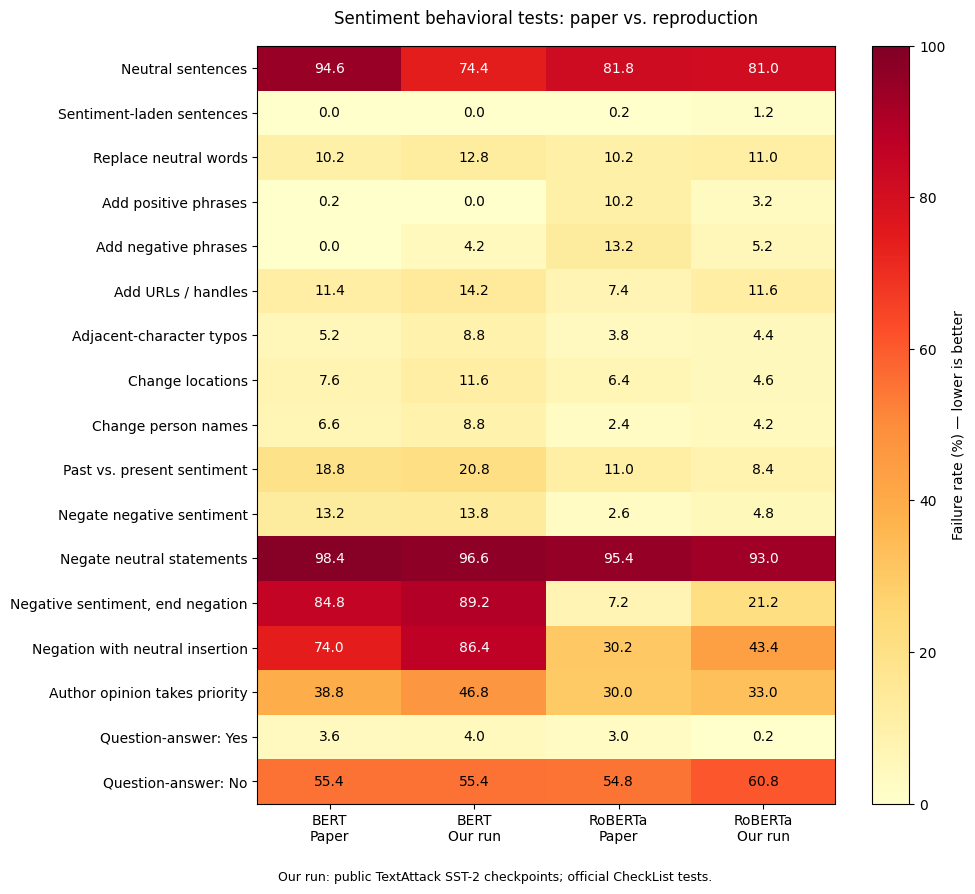

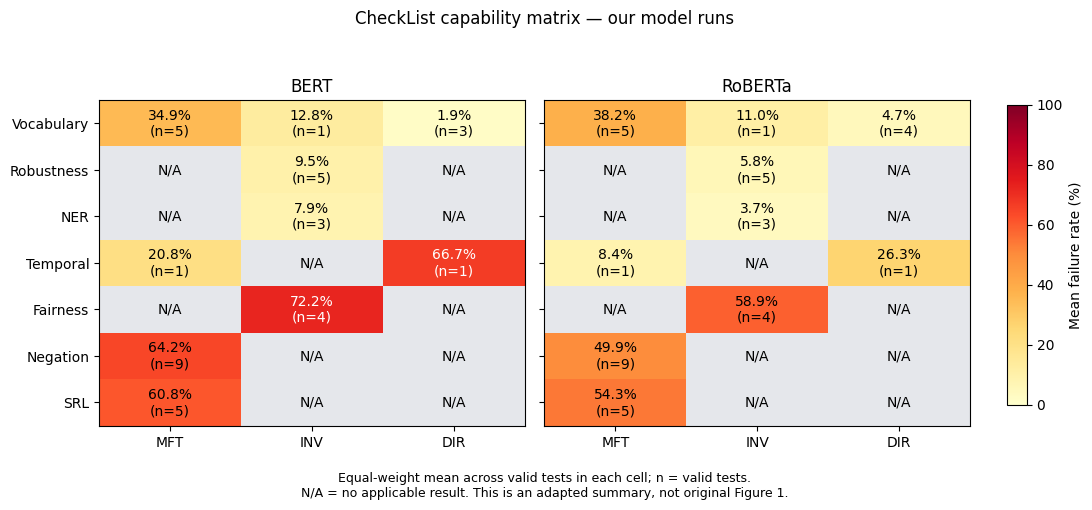

FIGURES_OK
图片和PDF保存到: /kaggle/working/member_a_results/figures


In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = Path("/kaggle/working/member_a_results")
FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)

comparison = pd.read_csv(OUT / "table1_reproduction_comparison.csv")
all_tests = pd.read_csv(OUT / "own_all_38_tests.csv")

assert len(comparison) == 17
assert len(all_tests) == 76  # 两个模型，各38项
assert not all_tests.duplicated(["model", "test"]).any()

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "savefig.dpi": 300,
})

# ---------- 图A：表1的17项测试 ----------
labels = [
    "Neutral sentences",
    "Sentiment-laden sentences",
    "Replace neutral words",
    "Add positive phrases",
    "Add negative phrases",
    "Add URLs / handles",
    "Adjacent-character typos",
    "Change locations",
    "Change person names",
    "Past vs. present sentiment",
    "Negate negative sentiment",
    "Negate neutral statements",
    "Negative sentiment, end negation",
    "Negation with neutral insertion",
    "Author opinion takes priority",
    "Question-answer: Yes",
    "Question-answer: No",
]

values = comparison[
    ["bert_paper_pct", "bert_own_pct",
     "roberta_paper_pct", "roberta_own_pct"]
].to_numpy(dtype=float)

assert np.isfinite(values).all()
assert ((values >= 0) & (values <= 100)).all()

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(values, cmap="YlOrRd", vmin=0, vmax=100, aspect="auto")

ax.set_xticks(range(4))
ax.set_xticklabels([
    "BERT\nPaper", "BERT\nOur run",
    "RoBERTa\nPaper", "RoBERTa\nOur run",
])
ax.set_yticks(range(17))
ax.set_yticklabels(labels)

for i in range(17):
    for j in range(4):
        value = values[i, j]
        ax.text(
            j, i, f"{value:.1f}",
            ha="center", va="center",
            color="white" if value >= 65 else "black",
        )

ax.set_title("Sentiment behavioral tests: paper vs. reproduction", pad=16)
fig.colorbar(im, ax=ax, label="Failure rate (%) — lower is better")
fig.text(
    0.5, 0.015,
    "Our run: public TextAttack SST-2 checkpoints; official CheckList tests.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIG / "table1_comparison.png", bbox_inches="tight")
fig.savefig(FIG / "table1_comparison.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)

# ---------- 图B：能力 × 测试类型 ----------
# N/A项目不参与平均；每项测试权重相同。
# n表示有效测试项目数，不是输入文本数或测试用例数。
capabilities = list(dict.fromkeys(all_tests["capability"]))
types = ["MFT", "INV", "DIR"]

fig, axes = plt.subplots(
    1, 2, figsize=(11, max(5, len(capabilities) * 0.65)),
    sharey=True,
)
summary_rows = []

cmap = plt.get_cmap("YlOrRd").copy()
cmap.set_bad("#e5e7eb")

for ax, model, title in zip(
    axes, ["bert", "roberta"], ["BERT", "RoBERTa"]
):
    subset = all_tests[all_tests["model"] == model]
    matrix = np.full((len(capabilities), len(types)), np.nan)
    counts = np.zeros_like(matrix, dtype=int)

    for i, capability in enumerate(capabilities):
        for j, test_type in enumerate(types):
            group = subset[
                (subset["capability"] == capability)
                & (subset["type"] == test_type)
            ]
            valid = group["failure_rate_pct"].dropna()
            counts[i, j] = len(valid)

            if len(valid):
                matrix[i, j] = valid.mean()

            summary_rows.append({
                "model": model,
                "capability": capability,
                "type": test_type,
                "n_tests_total": len(group),
                "n_tests_valid": len(valid),
                "macro_failure_rate_pct": matrix[i, j],
            })

    im = ax.imshow(
        np.ma.masked_invalid(matrix),
        cmap=cmap, vmin=0, vmax=100, aspect="auto",
    )

    for i in range(len(capabilities)):
        for j in range(len(types)):
            value = matrix[i, j]
            text = "N/A" if np.isnan(value) else (
                f"{value:.1f}%\n(n={counts[i, j]})"
            )
            ax.text(
                j, i, text, ha="center", va="center",
                color="white" if np.isfinite(value) and value >= 65
                else "black",
            )

    ax.set_xticks(range(3))
    ax.set_xticklabels(types)
    ax.set_yticks(range(len(capabilities)))
    ax.set_yticklabels(capabilities)
    ax.set_title(title)

fig.suptitle("CheckList capability matrix — our model runs", y=0.99)
fig.text(
    0.5, 0.015,
    "Equal-weight mean across valid tests in each cell; n = valid tests.\n"
    "N/A = no applicable result. This is an adapted summary, not original Figure 1.",
    ha="center", fontsize=9,
)
fig.tight_layout(rect=(0, 0.08, 0.9, 0.95))
cax = fig.add_axes([0.92, 0.20, 0.018, 0.60])
fig.colorbar(im, cax=cax, label="Mean failure rate (%)")

fig.savefig(FIG / "capability_matrix.png", bbox_inches="tight")
fig.savefig(FIG / "capability_matrix.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)

pd.DataFrame(summary_rows).to_csv(
    OUT / "capability_matrix_values.csv",
    index=False,
    encoding="utf-8-sig",
)

print("FIGURES_OK")
print("图片和PDF保存到:", FIG)

In [11]:
from pathlib import Path
import zipfile
from IPython.display import display, FileLink

base = Path("/kaggle/working")
fig_dir = base / "member_a_results/figures"

names = [
    "table1_comparison.png",
    "table1_comparison.pdf",
    "capability_matrix.png",
    "capability_matrix.pdf",
]

for name in names:
    assert (fig_dir / name).is_file(), f"缺少文件：{name}"

archive = base / "member_a_figures.zip"
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
    for name in names:
        z.write(fig_dir / name, arcname=name)

%cd /kaggle/working

print("点击这个链接，一次下载全部图片：")
display(FileLink("member_a_figures.zip"))

print("\n也可以单独下载：")
for name in names:
    display(FileLink(f"member_a_results/figures/{name}"))

/kaggle/working
点击这个链接，一次下载全部图片：


/kaggle/working/member_a_figures.zip


也可以单独下载：


/kaggle/working/member_a_results/figures/table1_comparison.png

/kaggle/working/member_a_results/figures/table1_comparison.pdf

/kaggle/working/member_a_results/figures/capability_matrix.png

/kaggle/working/member_a_results/figures/capability_matrix.pdf

In [12]:
import subprocess
from pathlib import Path

OUT = Path("/kaggle/working/member_a_results")

case_code = r'''
import sys
import json
import csv
import numpy as np
from pathlib import Path

sys.path.insert(0, "/kaggle/working/checklist")
from checklist.test_suite import TestSuite

out = Path("/kaggle/working/member_a_results")
ref = out / "reference"

selected = [
    ("中性短句",
     "neutral words in context",
     "neutral"),
    ("否定中性表达",
     "simple negations: not neutral is still neutral",
     "neutral"),
    ("句末否定负面表达",
     "simple negations: I thought x was negative, but it was not (should be neutral or positive)",
     "neutral or positive"),
    ("插入中性内容的否定",
     "Hard: Negation of positive with neutral stuff in the middle (should be negative)",
     "negative"),
    ("作者观点优先",
     "my opinion is what matters",
     "see suite label"),
]

suites = {}
for model in ["bert", "roberta"]:
    suite = TestSuite.from_file(str(ref / "sentiment_suite.pkl"))
    suite.run_from_file(
        str(out / f"{model}_own_predictions.txt"),
        overwrite=True,
    )
    suites[model] = suite

label_names = {0: "negative", 1: "neutral", 2: "positive"}

def data_index(test, result_index):
    if test.run_idxs is None:
        return int(result_index)
    return int(test.run_idxs[result_index])

def expected_label(test, idx, fallback):
    labels = test.labels
    if labels is None:
        return fallback
    if isinstance(labels, (list, tuple, np.ndarray)):
        value = labels[idx]
    else:
        value = labels
    if np.isscalar(value):
        return label_names.get(int(value), str(value))
    return str(value)

records = []

for title, name, fallback in selected:
    bert = suites["bert"].tests[name]
    roberta = suites["roberta"].tests[name]

    b_ids = (
        list(range(len(bert.data))) if bert.run_idxs is None
        else [int(x) for x in bert.run_idxs]
    )
    r_ids = (
        list(range(len(roberta.data))) if roberta.run_idxs is None
        else [int(x) for x in roberta.run_idxs]
    )
    assert b_ids == r_ids, "两个模型的抽样索引不一致"

    b_fails = set(int(x) for x in bert.fail_idxs())
    r_fails = set(int(x) for x in roberta.fail_idxs())

    # 每类最多取两个案例：
    # 共同失败的第一个，以及只有一个模型失败的第一个。
    groups = [
        ("both_fail", sorted(b_fails & r_fails)),
        ("one_model_fails", sorted(b_fails ^ r_fails)),
    ]

    for category, candidates in groups:
        if not candidates:
            continue

        result_idx = candidates[0]
        idx = data_index(bert, result_idx)
        text = bert.data[idx]
        assert isinstance(text, str), "本单元仅提取单句MFT案例"
        assert text == roberta.data[idx]

        record = {
            "test_zh": title,
            "official_test_name": name,
            "selection": category,
            "suite_data_index": idx,
            "text": text,
            "expected": expected_label(bert, idx, fallback),
        }

        for model, test, fails in [
            ("bert", bert, b_fails),
            ("roberta", roberta, r_fails),
        ]:
            prediction = int(test.results.preds[idx])
            confs = np.asarray(test.results.confs[idx], dtype=float)
            assert confs.shape == (3,)
            record[f"{model}_prediction"] = label_names[prediction]
            record[f"{model}_failed"] = result_idx in fails
            record[f"{model}_confs"] = confs.tolist()

        records.append(record)

        print("\n测试:", title)
        print("案例选择:", category)
        print("输入:", text)
        print("期望:", record["expected"])
        for model in ["bert", "roberta"]:
            state = "FAIL" if record[f"{model}_failed"] else "PASS"
            probs = ", ".join(
                f"{x:.4f}" for x in record[f"{model}_confs"]
            )
            print(
                f"{model}: {record[f'{model}_prediction']} | {state}"
                f" | [负面, 中性, 正面]=[{probs}]"
            )

assert records, "没有提取到案例"

(out / "failure_cases.json").write_text(
    json.dumps(records, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

with (out / "failure_cases.csv").open(
    "w", newline="", encoding="utf-8-sig"
) as f:
    writer = csv.DictWriter(f, fieldnames=list(records[0]))
    writer.writeheader()
    writer.writerows(records)

print("\nFAILURE_CASES_OK")
'''

script = OUT / "extract_failure_cases.py"
script.write_text(case_code, encoding="utf-8")

result = subprocess.run(
    ["/kaggle/working/checklist-py37/bin/python", "-u", str(script)],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    errors="replace",
)

(OUT / "failure_cases.log").write_text(
    result.stdout, encoding="utf-8"
)
print("退出码:", result.returncode)
print(result.stdout)

退出码: 0

测试: 中性短句
案例选择: both_fail
输入: That was an international crew.
期望: neutral
bert: positive | FAIL | [负面, 中性, 正面]=[0.0057, 0.0000, 0.9943]
roberta: positive | FAIL | [负面, 中性, 正面]=[0.0840, 0.0000, 0.9160]

测试: 中性短句
案例选择: one_model_fails
输入: That pilot is British.
期望: neutral
bert: neutral | PASS | [负面, 中性, 正面]=[0.3827, 0.6173, 0.0000]
roberta: positive | FAIL | [负面, 中性, 正面]=[0.2471, 0.0000, 0.7529]

测试: 否定中性表达
案例选择: both_fail
输入: That was not an Australian pilot.
期望: neutral
bert: negative | FAIL | [负面, 中性, 正面]=[0.9908, 0.0000, 0.0092]
roberta: negative | FAIL | [负面, 中性, 正面]=[0.7402, 0.0000, 0.2598]

测试: 否定中性表达
案例选择: one_model_fails
输入: It is not an Israeli crew.
期望: neutral
bert: negative | FAIL | [负面, 中性, 正面]=[0.9801, 0.0000, 0.0199]
roberta: neutral | PASS | [负面, 中性, 正面]=[0.2126, 0.7874, 0.0000]

测试: 句末否定负面表达
案例选择: both_fail
输入: I thought this cabin crew would be creepy, but it was not.
期望: neutral or positive
bert: negative | FAIL | [负面, 中性, 正面]=[0.9845, 0.0000, 0.0155]
roberta:

In [13]:
from pathlib import Path
import shutil
import zipfile
from IPython.display import display, FileLink

base = Path("/kaggle/working")
out = base / "member_a_results"

required = [
    "experiment_config.json",
    "bert_own_predictions.txt",
    "roberta_own_predictions.txt",
    "own_all_38_tests.csv",
    "table1_reproduction_comparison.csv",
    "capability_matrix_values.csv",
    "failure_cases.json",
    "failure_cases.csv",
    "figures/table1_comparison.png",
    "figures/table1_comparison.pdf",
    "figures/capability_matrix.png",
    "figures/capability_matrix.pdf",
    "run_bert_resumable.py",
    "run_roberta_resumable.py",
    "score_checklist.py",
    "extract_failure_cases.py",
    "scoring_requirements.txt",
]

missing = [name for name in required if not (out / name).is_file()]
assert not missing, f"缺少文件：{missing}"

archive = shutil.make_archive(
    str(base / "member_a_final_results"),
    "zip",
    str(base),
    "member_a_results",
)

with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None

print("成果文件检查通过")
print(f"备份大小：{Path(archive).stat().st_size / 1024**2:.2f} MB")
print("请手动下载并确认电脑中存在该文件。")

%cd /kaggle/working
display(FileLink("member_a_final_results.zip"))

成果文件检查通过
备份大小：8.17 MB
请手动下载并确认电脑中存在该文件。
/kaggle/working


/kaggle/working/member_a_final_results.zip